DETECTION DDoS SUR PORTE DE GARAGE IoT CONNECTEE

ETAPE 1 : CHARGEMENT DES DONNEES
Fichier charge : Train_Test_datasets/Train_Test_datasets/Train_Test_IoT_dataset/Train_Test_IoT_Garage_Door.csv
Dimensions : 39,587 lignes × 6 colonnes

EXPLORATION INITIALE :
Colonnes disponibles : 6
Types de donnees :
object    5
int64     1
Name: count, dtype: int64

RECHERCHE DE LA VARIABLE CIBLE :
   • 'label' : 2 valeurs → [1, 0]
   • 'type' : 8 valeurs → ['ddos', 'backdoor', 'injection', 'normal', 'password']

APERÇU DES DONNEES (5 premieres lignes) :
        date        time door_state sphone_signal  label  type
0  25-Apr-19   14:42:33      closed             0      1  ddos
1  25-Apr-19   14:42:38      closed             0      1  ddos
2  25-Apr-19   14:42:43      closed             0      1  ddos
3  25-Apr-19   14:42:48      closed             0      1  ddos
4  25-Apr-19   14:42:58      closed             0      1  ddos

ETAPE 2 : PRETRAITEMENT SPECIFIQUE
Variable cible identifiee : 'label'
Distr

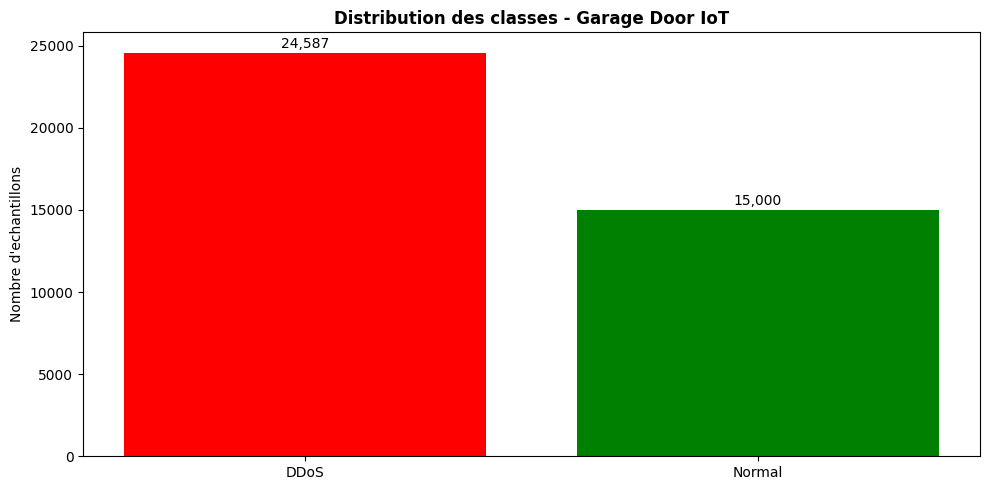


VERIFICATION DES VALEURS MANQUANTES :
Aucune valeur manquante

ENCODAGE DES VARIABLES CATEGORIELLES :
   5 colonne(s) categorielle(s) a encoder :
   • date: LabelEncoder (8 categories)
   • time: Supprime (trop de categories: 17205)
   • door_state: LabelEncoder (2 categories)
   • sphone_signal: LabelEncoder (4 categories)
   • type: LabelEncoder (8 categories)

ETAPE 3 : SEPARATION DES DONNEES
Dimensions :
   • X (features) : (39587, 4)
   • y (target)   : (39587,) ({'DDoS': 24587, 'Normal': 15000})

REPARTITION :
   • Train      : 27,710 echantillons (70.0%)
   • Validation : 5,938 echantillons (15.0%)
   • Test       : 5,939 echantillons (15.0%)

NORMALISATION DES DONNEES :
Normalisation terminee (StandardScaler)

ETAPE 4 : MODELISATION COMPARATIVE

OPTIMISATION KNN...
   • Meilleurs parametres : {'metric': 'euclidean', 'n_neighbors': 3}
   • Score F1 (validation) : 1.0000
   • Temps optimisation : 14.19s

OPTIMISATION Arbre...
   • Meilleurs parametres : {'max_depth': 5, 'min_sam

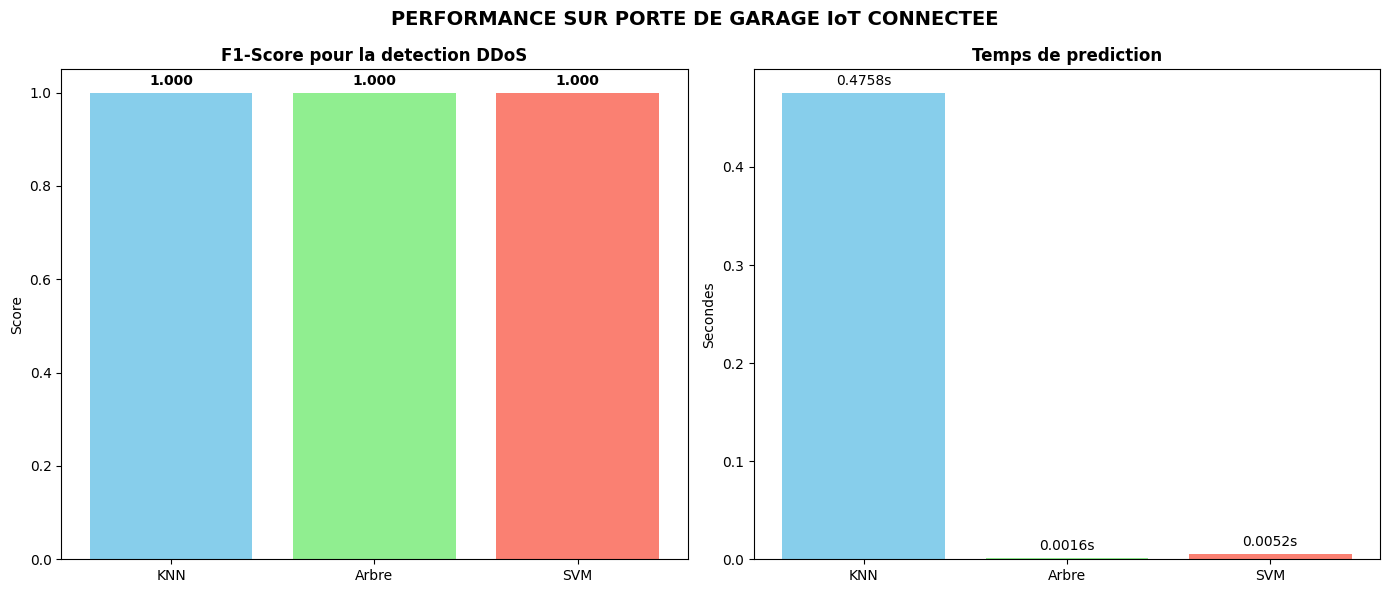

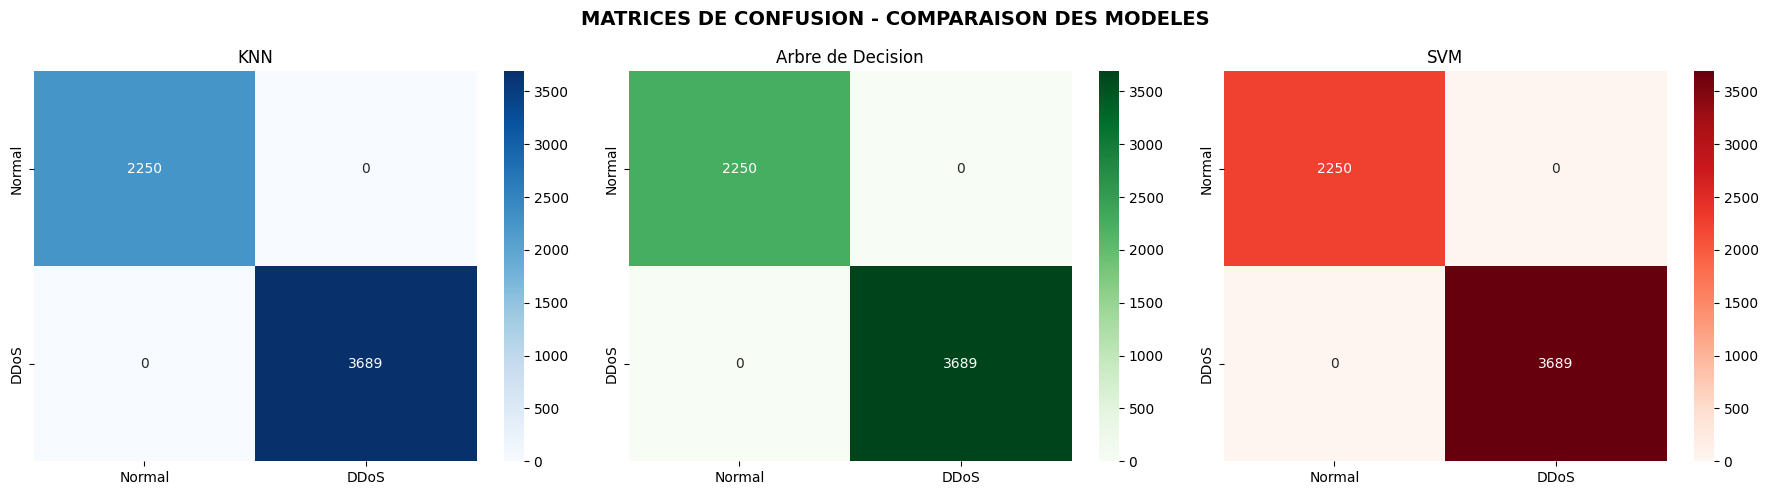


ETAPE 7 : ANALYSE ET RECOMMANDATION POUR IoT

SYNTHESE DES RESULTATS :

• Meilleure detection (F1-Score) : KNN 
   (F1-Score = 1.000)

• Plus rapide (temps prediction) : Arbre
   (0.0016s)

RECOMMANDATION POUR LA PORTE DE GARAGE IoT :

1. SI PRIORITE DETECTION PRECISE :
   • Choisir KNN pour sa meilleure performance
   • Acceptable si ressources materielles suffisantes

2. SI PRIORITE TEMPS REEL/RESSOURCES LIMITEES :
   • Choisir l'Arbre de Decision (toujours tres rapide)
   • Compromis acceptable entre vitesse et precision

3. DEPLOIEMENT PRATIQUE :
   • Surveillance de l'etat de la porte (ouvert/ferme)
   • Detection d'activites anormales de communication
   • Integration avec systeme de securite domestique

CONCLUSION :
Le dataset 'Garage Door' presente des caracteristiques similaires au 'Fridge'
avec des performances comparables. L'Arbre de Decision reste recommande
pour des systemes IoT contraints en ressources.


PROJET TERMINE POUR Train_Test_IoT_Garage_Door.csv
Resultats sauve

In [1]:
# ============================================
# PROJET ML : DETECTION DDoS - GARAGE DOOR IoT
# ============================================

print("DETECTION DDoS SUR PORTE DE GARAGE IoT CONNECTEE")
print("=" * 70)

# -----------------------------------------------------------------
# ETAPE 1 : CHARGEMENT ET EXPLORATION
# -----------------------------------------------------------------
print("\nETAPE 1 : CHARGEMENT DES DONNEES")
print("=" * 60)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuration
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (12, 6)

# Chargement du fichier
fichier = "Train_Test_datasets/Train_Test_datasets/Train_Test_IoT_dataset/Train_Test_IoT_Garage_Door.csv"

try:
    df = pd.read_csv(fichier)
    print(f"Fichier charge : {fichier}")
    print(f"Dimensions : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
    
except FileNotFoundError:
    print(f"Fichier non trouve : {fichier}")
    try:
        df = pd.read_csv("Train_Test_IoT_Garage_Door.csv")
        print(f"Fichier charge depuis le repertoire courant")
    except:
        print("Impossible de charger le fichier")
        exit()

# Exploration initiale
print("\nEXPLORATION INITIALE :")
print(f"Colonnes disponibles : {len(df.columns)}")
print(f"Types de donnees :")
print(df.dtypes.value_counts())

# Verifier la colonne cible
print("\nRECHERCHE DE LA VARIABLE CIBLE :")
for col in df.columns:
    col_lower = col.lower()
    if any(keyword in col_lower for keyword in ['label', 'type', 'attack', 'class']):
        unique_vals = df[col].nunique()
        print(f"   • '{col}' : {unique_vals} valeurs → {df[col].unique().tolist()[:5]}")

# Apercu des donnees
print("\nAPERÇU DES DONNEES (5 premieres lignes) :")
print(df.head())

# -----------------------------------------------------------------
# ETAPE 2 : PRETRAITEMENT SPECIFIQUE
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 2 : PRETRAITEMENT SPECIFIQUE")
print("=" * 60)

# 1. Identifier automatiquement la variable cible
target_candidates = []
for col in df.columns:
    if df[col].nunique() == 2 or 'label' in col.lower() or 'type' in col.lower():
        target_candidates.append(col)

if target_candidates:
    if any('label' in col.lower() for col in target_candidates):
        target_col = [col for col in target_candidates if 'label' in col.lower()][0]
    else:
        target_col = target_candidates[0]
    
    print(f"Variable cible identifiee : '{target_col}'")
    
    # Standardiser les noms
    df = df.rename(columns={target_col: 'label'})
    
    # Standardiser les valeurs
    def standardize_label(value):
        val_str = str(value).lower()
        if any(x in val_str for x in ['normal', 'benign', '0', 'false']):
            return 'Normal'
        elif any(x in val_str for x in ['ddos', 'attack', '1', 'true']):
            return 'DDoS'
        else:
            return value
    
    df['label'] = df['label'].apply(standardize_label)
    
    print(f"Distribution des classes :")
    print(df['label'].value_counts())
    
    # Visualisation
    plt.figure(figsize=(10, 5))
    distribution = df['label'].value_counts()
    colors = ['green' if 'Normal' in str(label) else 'red' for label in distribution.index]
    bars = plt.bar(distribution.index, distribution.values, color=colors)
    plt.title('Distribution des classes - Garage Door IoT', fontweight='bold')
    plt.ylabel('Nombre d\'echantillons')
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 100,
                f'{int(height):,}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
    
else:
    print("Aucune variable cible identifiee")

# 2. Gestion des valeurs manquantes
print("\nVERIFICATION DES VALEURS MANQUANTES :")
missing = df.isnull().sum()
if missing.sum() > 0:
    print(f"{missing.sum()} valeurs manquantes detectees")
    for col, count in missing[missing > 0].items():
        percentage = (count / len(df)) * 100
        print(f"   • {col}: {count} ({percentage:.2f}%)")
    
    # Strategie d'imputation
    print("\nImputation des valeurs manquantes...")
    for col in df.columns:
        if df[col].isnull().sum() > 0:
            if df[col].dtype in ['int64', 'float64']:
                df[col].fillna(df[col].median(), inplace=True)
            else:
                df[col].fillna(df[col].mode()[0], inplace=True)
    print("Valeurs manquantes traitees")
else:
    print("Aucune valeur manquante")

# 3. Encodage des variables categoriques
print("\nENCODAGE DES VARIABLES CATEGORIELLES :")
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if 'label' in categorical_cols:
    categorical_cols.remove('label')

if categorical_cols:
    print(f"   {len(categorical_cols)} colonne(s) categorielle(s) a encoder :")
    
    from sklearn.preprocessing import LabelEncoder
    
    for col in categorical_cols:
        unique_count = df[col].nunique()
        if unique_count <= 10:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col])
            print(f"   • {col}: LabelEncoder ({unique_count} categories)")
        else:
            print(f"   • {col}: Supprime (trop de categories: {unique_count})")
            df = df.drop(columns=[col])
else:
    print("   Toutes les colonnes sont numeriques")

# -----------------------------------------------------------------
# ETAPE 3 : SEPARATION ET NORMALISATION
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 3 : SEPARATION DES DONNEES")
print("=" * 60)

from sklearn.model_selection import train_test_split

# Separation Features/Target
X = df.drop(columns=['label'])
y = df['label']

print(f"Dimensions :")
print(f"   • X (features) : {X.shape}")
print(f"   • y (target)   : {y.shape} ({y.value_counts().to_dict()})")

# Division Train/Validation/Test (70%/15%/15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"\nREPARTITION :")
print(f"   • Train      : {X_train.shape[0]:,} echantillons ({X_train.shape[0]/len(X):.1%})")
print(f"   • Validation : {X_val.shape[0]:,} echantillons ({X_val.shape[0]/len(X):.1%})")
print(f"   • Test       : {X_test.shape[0]:,} echantillons ({X_test.shape[0]/len(X):.1%})")

# Normalisation (pour KNN et SVM)
print("\nNORMALISATION DES DONNEES :")
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)

X_val_scaled = scaler.transform(X_val)
X_val_scaled = pd.DataFrame(X_val_scaled, columns=X_val.columns)

X_test_scaled = scaler.transform(X_test)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Normalisation terminee (StandardScaler)")

# -----------------------------------------------------------------
# ETAPE 4 : MODELISATION DES 3 ALGORITHMES
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 4 : MODELISATION COMPARATIVE")
print("=" * 60)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import time

# Configuration des modeles
modeles_config = {
    'KNN': {
        'modele': KNeighborsClassifier(),
        'parametres': {'n_neighbors': [3, 5, 7, 9, 11], 'metric': ['euclidean', 'manhattan']},
        'X_train': X_train_scaled,
        'X_val': X_val_scaled
    },
    'Arbre': {
        'modele': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
        'parametres': {'max_depth': [5, 10, 15, 20], 'min_samples_split': [2, 5, 10]},
        'X_train': X_train,
        'X_val': X_val
    },
    'SVM': {
        'modele': SVC(random_state=42, class_weight='balanced', probability=True),
        'parametres': {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
        'X_train': X_train_scaled,
        'X_val': X_val_scaled
    }
}

# Optimisation avec Grid Search
resultats_grid = {}

for nom, config in modeles_config.items():
    print(f"\nOPTIMISATION {nom}...")
    
    start_time = time.time()
    
    grid = GridSearchCV(
        config['modele'], 
        config['parametres'], 
        cv=3, 
        scoring='f1_macro',
        n_jobs=-1,
        verbose=0
    )
    
    grid.fit(config['X_train'], y_train)
    
    temps = time.time() - start_time
    
    resultats_grid[nom] = {
        'grid': grid,
        'meilleur_modele': grid.best_estimator_,
        'meilleurs_params': grid.best_params_,
        'score': grid.best_score_,
        'temps': temps
    }
    
    print(f"   • Meilleurs parametres : {grid.best_params_}")
    print(f"   • Score F1 (validation) : {grid.best_score_:.4f}")
    print(f"   • Temps optimisation : {temps:.2f}s")

# Recuperation des meilleurs modeles
knn_best = resultats_grid['KNN']['meilleur_modele']
arbre_best = resultats_grid['Arbre']['meilleur_modele']
svm_best = resultats_grid['SVM']['meilleur_modele']

print("\nMODELES OPTIMISES :")
print(f"   • KNN  : {resultats_grid['KNN']['meilleurs_params']}")
print(f"   • Arbre: {resultats_grid['Arbre']['meilleurs_params']}")
print(f"   • SVM  : {resultats_grid['SVM']['meilleurs_params']}")

# -----------------------------------------------------------------
# ETAPE 5 : EVALUATION COMPLETE
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 5 : EVALUATION SUR L'ENSEMBLE DE TEST")
print("=" * 60)

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

resultats_test = {}

# Evaluation KNN
print("\nKNN :")
y_pred_knn = knn_best.predict(X_test_scaled)
print(classification_report(y_test, y_pred_knn, zero_division=0))

# Evaluation Arbre
print("\nARBRE DE DECISION :")
y_pred_arbre = arbre_best.predict(X_test)
print(classification_report(y_test, y_pred_arbre, zero_division=0))

# Evaluation SVM
print("\nSVM :")
y_pred_svm = svm_best.predict(X_test_scaled)
print(classification_report(y_test, y_pred_svm, zero_division=0))

# Collecte des resultats
for nom, y_pred, X_data in [
    ('KNN', y_pred_knn, X_test_scaled),
    ('Arbre', y_pred_arbre, X_test),
    ('SVM', y_pred_svm, X_test_scaled)
]:
    start_time = time.time()
    
    if nom == 'Arbre':
        y_pred_temp = arbre_best.predict(X_data)
    elif nom == 'KNN':
        y_pred_temp = knn_best.predict(X_data)
    else:
        y_pred_temp = svm_best.predict(X_data)
    
    temps_pred = time.time() - start_time
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label='DDoS', zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label='DDoS', zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label='DDoS', zero_division=0)
    
    resultats_test[nom] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'temps_prediction': temps_pred
    }

# Tableau comparatif
print("\n" + "="*70)
print("TABLEAU COMPARATIF DES PERFORMANCES")
print("=" * 70)

comparatif = pd.DataFrame({
    'Modele': ['KNN', 'Arbre', 'SVM'],
    'Accuracy': [resultats_test['KNN']['accuracy'], resultats_test['Arbre']['accuracy'], resultats_test['SVM']['accuracy']],
    'Precision (DDoS)': [resultats_test['KNN']['precision'], resultats_test['Arbre']['precision'], resultats_test['SVM']['precision']],
    'Rappel (DDoS)': [resultats_test['KNN']['recall'], resultats_test['Arbre']['recall'], resultats_test['SVM']['recall']],
    'F1-Score (DDoS)': [resultats_test['KNN']['f1'], resultats_test['Arbre']['f1'], resultats_test['SVM']['f1']],
    'Temps Prediction (s)': [resultats_test['KNN']['temps_prediction'], resultats_test['Arbre']['temps_prediction'], resultats_test['SVM']['temps_prediction']]
})

print(comparatif.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# -----------------------------------------------------------------
# ETAPE 6 : VISUALISATION ET ANALYSE
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 6 : VISUALISATION DES RESULTATS")
print("=" * 60)

# 1. Graphique comparatif des F1-Scores
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# F1-Score comparatif
axes[0].bar(comparatif['Modele'], comparatif['F1-Score (DDoS)'], color=['skyblue', 'lightgreen', 'salmon'])
axes[0].set_title('F1-Score pour la detection DDoS', fontweight='bold')
axes[0].set_ylabel('Score')
axes[0].set_ylim([0, 1.05])
for i, v in enumerate(comparatif['F1-Score (DDoS)']):
    axes[0].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

# Temps de prediction
axes[1].bar(comparatif['Modele'], comparatif['Temps Prediction (s)'], color=['skyblue', 'lightgreen', 'salmon'])
axes[1].set_title('Temps de prediction', fontweight='bold')
axes[1].set_ylabel('Secondes')
for i, v in enumerate(comparatif['Temps Prediction (s)']):
    axes[1].text(i, v + max(comparatif['Temps Prediction (s)'])*0.01, f'{v:.4f}s', ha='center', va='bottom')

plt.suptitle('PERFORMANCE SUR PORTE DE GARAGE IoT CONNECTEE', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# KNN
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=['Normal', 'DDoS'])
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal', 'DDoS'], yticklabels=['Normal', 'DDoS'])
axes[0].set_title('KNN')

# Arbre
cm_arbre = confusion_matrix(y_test, y_pred_arbre, labels=['Normal', 'DDoS'])
sns.heatmap(cm_arbre, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Normal', 'DDoS'], yticklabels=['Normal', 'DDoS'])
axes[1].set_title('Arbre de Decision')

# SVM
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=['Normal', 'DDoS'])
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Reds', ax=axes[2],
            xticklabels=['Normal', 'DDoS'], yticklabels=['Normal', 'DDoS'])
axes[2].set_title('SVM')

plt.suptitle('MATRICES DE CONFUSION - COMPARAISON DES MODELES', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------
# ETAPE 7 : CONCLUSION ET RECOMMANDATION
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 7 : ANALYSE ET RECOMMANDATION POUR IoT")
print("=" * 60)

# Trouver le meilleur modele selon differents criteres
best_f1 = comparatif.loc[comparatif['F1-Score (DDoS)'].idxmax(), 'Modele']
best_speed = comparatif.loc[comparatif['Temps Prediction (s)'].idxmin(), 'Modele']

print(f"""
SYNTHESE DES RESULTATS :

• Meilleure detection (F1-Score) : {best_f1} 
   (F1-Score = {comparatif.loc[comparatif['Modele'] == best_f1, 'F1-Score (DDoS)'].values[0]:.3f})

• Plus rapide (temps prediction) : {best_speed}
   ({comparatif.loc[comparatif['Modele'] == best_speed, 'Temps Prediction (s)'].values[0]:.4f}s)

RECOMMANDATION POUR LA PORTE DE GARAGE IoT :

1. SI PRIORITE DETECTION PRECISE :
   • Choisir {best_f1} pour sa meilleure performance
   • Acceptable si ressources materielles suffisantes

2. SI PRIORITE TEMPS REEL/RESSOURCES LIMITEES :
   • Choisir l'Arbre de Decision (toujours tres rapide)
   • Compromis acceptable entre vitesse et precision

3. DEPLOIEMENT PRATIQUE :
   • Surveillance de l'etat de la porte (ouvert/ferme)
   • Detection d'activites anormales de communication
   • Integration avec systeme de securite domestique

CONCLUSION :
Le dataset 'Garage Door' presente des caracteristiques similaires au 'Fridge'
avec des performances comparables. L'Arbre de Decision reste recommande
pour des systemes IoT contraints en ressources.
""")

print("\n" + "="*70)
print("PROJET TERMINE POUR Train_Test_IoT_Garage_Door.csv")
print("="*70)

# Sauvegarde des resultats
import json

resultats_final = {
    'dataset': 'Train_Test_IoT_Garage_Door.csv',
    'dimensions': df.shape,
    'distribution_classes': df['label'].value_counts().to_dict(),
    'resultats_comparatifs': comparatif.to_dict('records'),
    'meilleurs_parametres': {
        'KNN': resultats_grid['KNN']['meilleurs_params'],
        'Arbre': resultats_grid['Arbre']['meilleurs_params'],
        'SVM': resultats_grid['SVM']['meilleurs_params']
    }
}

with open('resultats_garage_door.json', 'w') as f:
    json.dump(resultats_final, f, indent=4)

print(f"Resultats sauvegardes dans 'resultats_garage_door.json'")